# Stage 6 – Extensions

**Input:** `data/processed/monitoring.csv`, `figures/table_frozen_recalibrated_reestimated.csv`, `data/processed/loans_clean.parquet` and `data/processed/scores.parquet`.

**Output:** two figures and three tables in `figures/`.

Two extensions of the main analysis:

1. a **Gaussian process** draws a smooth curve with an uncertainty band through the quarterly results, to separate a real decline from quarter-to-quarter noise (the *when*);
2. **clustering** groups the borrowers into a few segments, to see how their mix changes and in which segment the models lose most (the *where*).

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter
from sklearn.cluster import KMeans
from sklearn.exceptions import ConvergenceWarning
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from helpers import (FIGURES, INK, INK_MUTED, INK_SOFT, LIGHT_COLORS, MODEL_COLORS, MODEL_LABELS, NUMERIC_FEATURES,
                     PROCESSED, SEED, gini, label_quarters, set_plot_style)

set_plot_style()

monitoring_results = pd.read_csv(PROCESSED / "monitoring.csv")
versions = pd.read_csv(FIGURES / "table_frozen_recalibrated_reestimated.csv")
scores = pd.read_parquet(PROCESSED / "scores.parquet")
loans = pd.read_parquet(PROCESSED / "loans_clean.parquet").merge(scores[["id", "sample", "pd_logit"]], on="id")

quarters = sorted(monitoring_results["issue_quarter"].unique())
TWO_MODELS = ["pd_logit", "pd_xgb"]

## 1. Gaussian process: is the decline real?

The Gini of a single quarter jumps up and down. A straight line through the 16 points would give a trend but would not say how sure we can be of it. A Gaussian process does both: it fits a smooth curve and gives a band around it.

The kernel has two parts, which is exactly the split we need:

- `RBF` is the smooth trend: quarters that are close in time have similar values. Its length scale says over how many quarters the curve can bend;
- `WhiteKernel` is the noise of each single quarter.

`predict` returns the uncertainty of a new noisy quarter. Removing the noise part leaves the uncertainty of the trend itself, which is the band to compare with a threshold.

In [2]:
def gp_trend(values):
    # One point per quarter: x is the position of the quarter (0, 1, ..., 15).
    values = np.asarray(values)
    x = np.arange(len(values)).reshape(-1, 1)
    # A trend should not bend faster than from one quarter to the next, so the length scale
    # cannot go below 1. scikit-learn warns when the best value sits on this limit.
    kernel = RBF(length_scale=4.0, length_scale_bounds=(1, 100)) + WhiteKernel(noise_level=0.5)
    gp = GaussianProcessRegressor(kernel=kernel, normalize_y=True, n_restarts_optimizer=5, random_state=SEED)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        gp.fit(x, values)

    mean, std = gp.predict(x, return_std=True)
    # normalize_y works on standardised values, so the noise goes back to the original scale.
    noise_std = np.sqrt(gp.kernel_.k2.noise_level) * values.std()
    trend_std = np.sqrt(np.maximum(std**2 - noise_std**2, 0))
    band = pd.DataFrame({"value": values, "trend": mean, "low": mean - 1.96 * trend_std, "high": mean + 1.96 * trend_std},
                        index=quarters)
    return band, gp.kernel_


def first_quarter(is_true):
    return is_true.idxmax() if is_true.any() else "never"

### 1.1 The Gini of the frozen models

The red threshold is the one of stage 4: 10% below the Gini on the development holdout. The decline is beyond doubt when the whole band is below the threshold.

In [3]:
holdout = scores[scores["sample"] == "holdout"]
gini_bands, summary = {}, []
for model in TWO_MODELS:
    series = monitoring_results[monitoring_results["model"] == model].set_index("issue_quarter")["gini"]
    band, kernel = gp_trend(series.loc[quarters])
    red_threshold = 0.9 * gini(holdout["target"], holdout[model])
    gini_bands[model] = (band, red_threshold)
    summary.append({
        "model": MODEL_LABELS[model], "kernel": str(kernel), "red_threshold": red_threshold,
        "trend_first_quarter": band["trend"].iloc[0], "trend_last_quarter": band["trend"].iloc[-1],
        "whole_band_below_red_from": first_quarter(band["high"] < red_threshold),
    })
summary = pd.DataFrame(summary).set_index("model")
summary.to_csv(FIGURES / "table_gp_gini.csv")
with pd.option_context("display.max_colwidth", None):
    display(summary.round(3))

,kernel,red_threshold,trend_first_quarter,trend_last_quarter,whole_band_below_red_from
model,,,,,
Logistic regression,RBF(length_scale=5.63) + WhiteKernel(noise_level=0.847),0.350,0.297,0.281,2012Q1
XGBoost,RBF(length_scale=1) + WhiteKernel(noise_level=0.287),0.364,0.300,0.275,2012Q1


### 1.2 The distance from a rebuilt model

The Gini of the frozen models is red from the first quarter, so the curve above cannot say how the models age. A better measure of ageing is the distance from a model rebuilt on the same quarter (stage 5, section 4): the Gini of the re-estimated model minus the Gini of the frozen one. At zero the old model is as good as a new one. The frozen model has aged beyond doubt when the whole band is above zero.

In [4]:
gap_bands, gap_summary = {}, []
for model in TWO_MODELS:
    wide = versions[versions["model"] == model].pivot(index="issue_quarter", columns="version", values="gini")
    gap = (wide["re-estimated"] - wide["frozen"]).loc[quarters]
    band, kernel = gp_trend(gap)
    gap_bands[model] = band
    gap_summary.append({
        "model": MODEL_LABELS[model], "kernel": str(kernel),
        "trend_first_quarter": band["trend"].iloc[0], "trend_last_quarter": band["trend"].iloc[-1],
        "whole_band_above_zero_from": first_quarter(band["low"] > 0),
    })
gap_summary = pd.DataFrame(gap_summary).set_index("model")
gap_summary.to_csv(FIGURES / "table_gp_gap.csv")
with pd.option_context("display.max_colwidth", None):
    display(gap_summary.round(3))

,kernel,trend_first_quarter,trend_last_quarter,whole_band_above_zero_from
model,,,,
Logistic regression,RBF(length_scale=3.2) + WhiteKernel(noise_level=0.313),-0.005,0.044,2012Q4
XGBoost,RBF(length_scale=3.11) + WhiteKernel(noise_level=0.223),-0.033,0.051,2013Q1


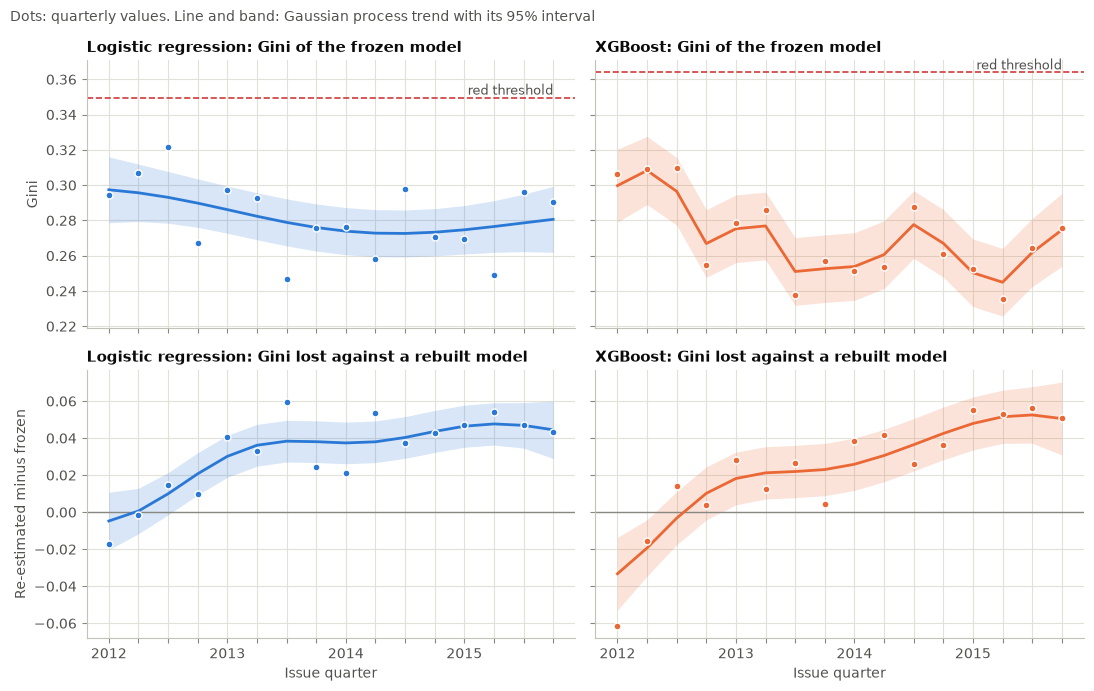

In [5]:
x = range(len(quarters))
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True, sharey="row")
for column, model in enumerate(TWO_MODELS):
    colour = MODEL_COLORS[model]

    band, red_threshold = gini_bands[model]
    ax = axes[0, column]
    ax.fill_between(x, band["low"], band["high"], color=colour, alpha=0.18, linewidth=0)
    ax.plot(x, band["trend"], color=colour)
    ax.scatter(x, band["value"], color=colour, s=25, zorder=3, edgecolors="white", linewidths=1)
    ax.axhline(red_threshold, color=LIGHT_COLORS["red"], linewidth=1.2, linestyle="--")
    ax.text(len(quarters) - 1, red_threshold, "red threshold", ha="right", va="bottom", color=INK_SOFT, fontsize=9)
    ax.set_title(f"{MODEL_LABELS[model]}: Gini of the frozen model")

    band = gap_bands[model]
    ax = axes[1, column]
    ax.axhline(0, color=INK_MUTED, linewidth=1)
    ax.fill_between(x, band["low"], band["high"], color=colour, alpha=0.18, linewidth=0)
    ax.plot(x, band["trend"], color=colour)
    ax.scatter(x, band["value"], color=colour, s=25, zorder=3, edgecolors="white", linewidths=1)
    ax.set_title(f"{MODEL_LABELS[model]}: Gini lost against a rebuilt model")
    ax.set_xlabel("Issue quarter")
    label_quarters(ax, quarters)
axes[0, 0].set_ylabel("Gini")
axes[1, 0].set_ylabel("Re-estimated minus frozen")
fig.suptitle("Dots: quarterly values. Line and band: Gaussian process trend with its 95% interval",
             x=0.01, ha="left", fontsize=10, color=INK_SOFT)
fig.tight_layout()
fig.savefig(FIGURES / "gp_trends.png")

**What section 1 says.** For the Gini itself the answer is the one of stage 4, now with the noise taken out: the trend of both models, band included, is below the red threshold from the first monitored quarter (2012Q1). The logistic trend moves slowly from 0.30 to 0.28. The XGBoost series bends at almost every quarter (its length scale sits on the lower limit of one quarter), so its curve follows the points closely.

The distance from a rebuilt model is the ageing curve. It starts at zero or below in 2012Q1, and its band is entirely above zero from 2012Q4 for the logistic regression and from 2013Q1 for XGBoost: the fourth and the fifth quarter after the end of development. From there it keeps growing, to 0.04-0.05 Gini in 2015. XGBoost starts lower and ends higher, so it ages faster.

## 2. Clustering: where does the decay concentrate?

### 2.1 How many segments

k-means is fitted on the thirteen numeric features of the development loans, standardised so that no feature dominates because of its unit. The silhouette (how much closer a loan is to its own cluster than to the nearest other one) is computed for k from 2 to 8. A handful of readable segments is worth more than a slightly better score with many, so k is the best value between 3 and 5.

In [6]:
development = loans[loans["sample"] != "monitoring"]
prepare = make_pipeline(SimpleImputer(strategy="median"), StandardScaler()).fit(development[NUMERIC_FEATURES])
development_standardised = prepare.transform(development[NUMERIC_FEATURES])

silhouettes = {}
for k in range(2, 9):
    labels = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(development_standardised)
    # The silhouette compares every pair of loans, so it is computed on a random sample of 5,000.
    silhouettes[k] = silhouette_score(development_standardised, labels, sample_size=5000, random_state=SEED)

K = max(range(3, 6), key=silhouettes.get)
print("Chosen number of clusters:", K)
pd.Series(silhouettes, name="silhouette").rename_axis("k").round(3).to_frame().T

Chosen number of clusters: 5


k,2,3,4,5,6,7,8
silhouette,0.132,0.12,0.137,0.14,0.13,0.113,0.111


### 2.2 Who is in each segment

The clusters are numbered by size on the development sample (1 is the largest). The profile is the average of each feature in the development sample, next to the share of loans and the default rate.

In [7]:
kmeans = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(development_standardised)
raw_cluster = kmeans.predict(prepare.transform(loans[NUMERIC_FEATURES]))

# Renumber the clusters from the largest to the smallest on the development sample.
development_sizes = pd.Series(raw_cluster[(loans["sample"] != "monitoring").to_numpy()]).value_counts()
new_number = {old: new for new, old in enumerate(development_sizes.index, start=1)}
loans["cluster"] = pd.Series(raw_cluster, index=loans.index).map(new_number)

development = loans[loans["sample"] != "monitoring"]
profile = development.groupby("cluster")[NUMERIC_FEATURES].mean()
profile.insert(0, "default_rate", development.groupby("cluster")["target"].mean())
profile.insert(0, "share_%", development["cluster"].value_counts(normalize=True) * 100)
profile.to_csv(FIGURES / "table_cluster_profiles.csv")
profile.T.round(2)

cluster,1,2,3,4,5
share_%,36.31,29.89,20.74,7.85,5.21
default_rate,0.14,0.09,0.07,0.14,0.18
loan_amnt,7699.83,13658.41,8133.35,8075.25,8066.78
log_annual_inc,10.69,11.33,10.84,10.97,10.92
dti,14.26,15.27,8.17,12.53,13.12
fico,698.79,724.30,754.05,689.61,693.49
emp_length_years,3.63,6.21,4.39,4.77,5.84
log_revol_bal,8.88,9.76,6.74,8.34,8.45
revol_util,64.40,49.37,15.78,46.12,55.72
open_acc,7.53,12.66,7.22,8.93,9.16


The names below were given by reading the profile table: each cluster is named after the features that set it apart. They must be checked again if the data or the seed change.

In [8]:
CLUSTER_NAMES = {
    1: "short history, high utilisation",
    2: "established, large credit file",
    3: "low utilisation, high FICO",
    4: "recent delinquencies",
    5: "public record",
}

### 2.3 The mix and the default rate over time

,share at development,share in 2015Q4
cluster,,
1,0.363,0.251
2,0.299,0.384
3,0.207,0.048
4,0.078,0.135
5,0.052,0.182


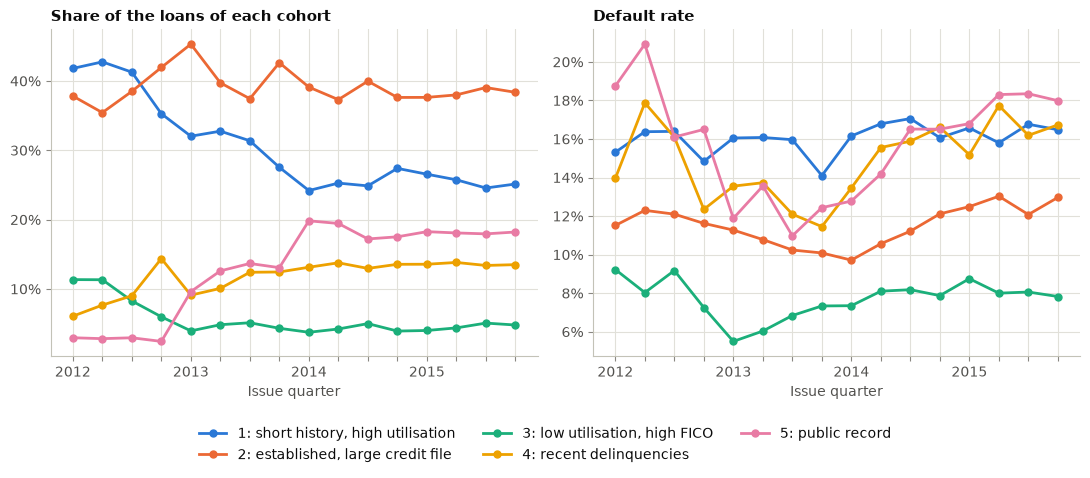

In [9]:
monitoring = loans[loans["sample"] == "monitoring"]
shares = pd.crosstab(monitoring["issue_quarter"], monitoring["cluster"], normalize="index")
default_rates = monitoring.pivot_table(index="issue_quarter", columns="cluster", values="target", aggfunc="mean")

CLUSTER_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
x = range(len(quarters))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, table, title in [(axes[0], shares, "Share of the loans of each cohort"),
                         (axes[1], default_rates, "Default rate")]:
    for cluster, colour in zip(table.columns, CLUSTER_COLORS):
        ax.plot(x, table[cluster], color=colour, marker="o", label=f"{cluster}: {CLUSTER_NAMES.get(cluster, '')}")
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_title(title)
    ax.set_xlabel("Issue quarter")
    label_quarters(ax, quarters)
fig.tight_layout()
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", bbox_to_anchor=(0.5, 0), ncol=3)
fig.savefig(FIGURES / "clusters_over_time.png")

pd.concat({"share at development": development["cluster"].value_counts(normalize=True).sort_index(),
           "share in 2015Q4": shares.loc[quarters[-1]]}, axis=1).round(3)

### 2.4 The frozen logistic regression inside each segment

The Gini and the calibration gap of the frozen logistic regression, cluster by cluster: on the development holdout and in each monitoring year. A cluster where the Gini falls more than elsewhere, or where the gap opens, is where the model ages fastest.

In [10]:
PERIODS = ["holdout", "2012", "2013", "2014", "2015"]
loans["period"] = np.where(loans["sample"] == "monitoring", loans["issue_year"].astype(str), loans["sample"])
rows = []
for period in PERIODS:
    for cluster, group in loans[loans["period"] == period].groupby("cluster"):
        rows.append({
            "cluster": cluster, "period": period, "loans": len(group),
            "gini": gini(group["target"], group["pd_logit"]),
            "calibration_gap": group["target"].mean() / group["pd_logit"].mean() - 1,
        })
by_cluster = pd.DataFrame(rows)
by_cluster.to_csv(FIGURES / "table_cluster_performance.csv", index=False)

pd.concat({measure: by_cluster.pivot(index="cluster", columns="period", values=measure)[PERIODS]
           for measure in ["loans", "gini", "calibration_gap"]}, axis=1).round(3)

loans                                gini                       \
period  holdout   2012   2013   2014   2015 holdout   2012   2013   2014   
cluster                                                                    
1          2043  15524  14845  12206  12238   0.272  0.243  0.240  0.228   
2          1707  15113  19815  18483  18365   0.392  0.292  0.300  0.309   
3          1195   3405   2185   2024   2188   0.447  0.414  0.434  0.338   
4           479   3849   5282   6408   6511   0.390  0.254  0.262  0.246   
5           284   1076   5873   8879   8698   0.274  0.270  0.201  0.203   

               calibration_gap                              
period    2015         holdout   2012   2013   2014   2015  
cluster                                                     
1        0.227           0.025  0.140  0.108  0.177  0.239  
2        0.314          -0.015  0.049 -0.066 -0.001  0.207  
3        0.409          -0.018  0.221  0.034  0.279  0.272  
4        0.201           0.005  0.040 -0.090  0.103  0.235  
5        0.202          -0.104  0.037 -0.314 -0.199 -0.014

**What section 2 says.** The silhouette is low for every k (0.11-0.14): the borrowers do not fall into sharply separated groups, so the clusters are a convenient way to cut the population rather than natural types. With five of them they are still easy to read.

The mix changes a lot. Cluster 3, the safest borrowers and the ones the model ranks best (Gini 0.45 on the holdout), falls from 21% of the development loans to 5% in 2015Q4. Clusters 4 and 5, the borrowers with recent delinquencies or a public record, grow from 13% to 32%, and there the frozen model ranks worst (Gini 0.20 in 2015). Part of the decay is therefore a matter of mix: the population moved towards the segments where the model is weakest.

The Gini also falls inside the segments, most of all in cluster 4 (0.39 to 0.20) and in cluster 2 (0.39 to 0.31), the largest one. In 2015 the model underestimates risk by 21-27% in four clusters out of five; in cluster 5 it does not (-1%), after overestimating it by 31% in 2013. The holdout figures of the small clusters rest on a few hundred loans (284 for cluster 5) and are only indicative.